# Underemployment Beyond Unemployment: Forecasting Underemployment Across Education Levels in the Philippines

## Project Background

Underemployment is an important labor issue because being employed does not always mean that a person has sufficient working hours or satisfactory employment. This project focuses on examining underemployment across different education levels in the Philippines using monthly data from the Philippine Statistics Authority (PSA).

The dataset covers January 2023 to December 2025 and contains underemployment and employment data for different education levels. The underemployment rate is calculated by comparing the number of underemployed workers with the number of employed workers within each education level.


## Project Objective

The main objective of this project is to forecast the next month's underemployment rate for each education level. The forecast can help identify patterns in underemployment and provide information that may support stakeholders such as labor planners, schools, and career guidance offices in understanding employment conditions across education groups.

The prediction target is the Underemployment Rate, where the target represents the rate for the following month. Historical underemployment rates, education level, and month are used as predictors because recent rates can capture trends while education level and month can account for differences between groups and monthly patterns.

The prepared dataset used in this notebook has 192 rows: 6 education tiers across 32 months (April 2023 to November 2025).

## Workflow

1. Load and check the prepared dataset
2. Explore the trends in each education tier
3. Define the predictors and the forecasting target
4. Split the data chronologically into training and testing sets
5. Train four regression models: Linear, Ridge, Lasso, and Random Forest
6. Evaluate the models using MAE, RMSE, and R² on training and testing data
7. Build a Lag 1 Persistence Baseline as a simple reference
8. Compare all models in one table
9. Check stability with rolling time series validation
10. Check for overfitting and underfitting
11. Visualize actual and predicted rates for past months (backtest)
12. Select and justify the final model
13. Forecast the next month (January 2026) for each education tier

## Part 1: Data Preparation

### 1.1 Import Libraries

Load the tools for data handling, charts, preprocessing, models, and evaluation metrics.

In [ ]:
# Import all libraries needed for data preparation,
# preprocessing, model training, and model evaluation.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


### 1.2 Load the Dataset

Load the prepared file `cleaned_underemployment_dataset.csv` (keep it in the same folder as this notebook, or upload it to Colab). The `Date` column is converted to datetime so the months can be sorted in order.

In [ ]:
# Load the prepared underemployment dataset.

df = pd.read_csv("cleaned_underemployment_dataset.csv")

# Convert Date back to datetime format.
df["Date"] = pd.to_datetime(df["Date"])

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
# Display the first five records of the prepared dataset.

df.head()

,Date,Year,Month,Underemployed,Employed,Education_Tier,Underemployment_Rate,National_Employment_Rate,National_Unemployment_Rate,National_Underemployment_Rate,Lag1_Rate,Lag2_Rate,Lag3_Rate,Rolling3_Rate,Target
0,2023-04-01,2023,April,1196.433,14141.994,College,8.460144,95.516,4.484,12.909,6.576540,7.820038,9.002297,7.799625,7.818555
1,2023-05-01,2023,May,1039.798,13299.107,College,7.818555,95.702,4.298,11.729,8.460144,6.576540,7.820038,7.618907,8.795430
2,2023-06-01,2023,June,1228.385,13966.174,College,8.795430,95.453,4.547,12.028,7.818555,8.460144,6.576540,7.618413,10.877109
3,2023-07-01,2023,July,1439.998,13238.793,College,10.877109,95.114,4.886,15.865,8.795430,7.818555,8.460144,8.358043,7.546481
4,2023-08-01,2023,August,1026.947,13608.290,College,7.546481,95.588,4.412,11.712,10.877109,8.795430,7.818555,9.163698,6.796500


### 1.3 Check the Data

Check the size of the dataset, the column names, and whether any values are missing.

In [ ]:
# Check the number of rows and columns in the prepared dataset.

print("Dataset shape:", df.shape)

# Display the column names.

print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (192, 15)

Columns:
['Date', 'Year', 'Month', 'Underemployed', 'Employed', 'Education_Tier', 'Underemployment_Rate', 'National_Employment_Rate', 'National_Unemployment_Rate', 'National_Underemployment_Rate', 'Lag1_Rate', 'Lag2_Rate', 'Lag3_Rate', 'Rolling3_Rate', 'Target']


In [ ]:
# Check whether the prepared dataset contains missing values.

print("Missing values:")
print(df.isnull().sum())

Missing values:
Date                             0
Year                             0
Month                            0
Underemployed                    0
Employed                         0
Education_Tier                   0
Underemployment_Rate             0
National_Employment_Rate         0
National_Unemployment_Rate       0
National_Underemployment_Rate    0
Lag1_Rate                        0
Lag2_Rate                        0
Lag3_Rate                        0
Rolling3_Rate                    0
Target                           0
dtype: int64


**Result:** The dataset has 192 rows and 15 columns, and none of the columns has missing values.

### 1.4 Explore the Trends

Before modeling, look at how the underemployment rate moves over time in each education tier.

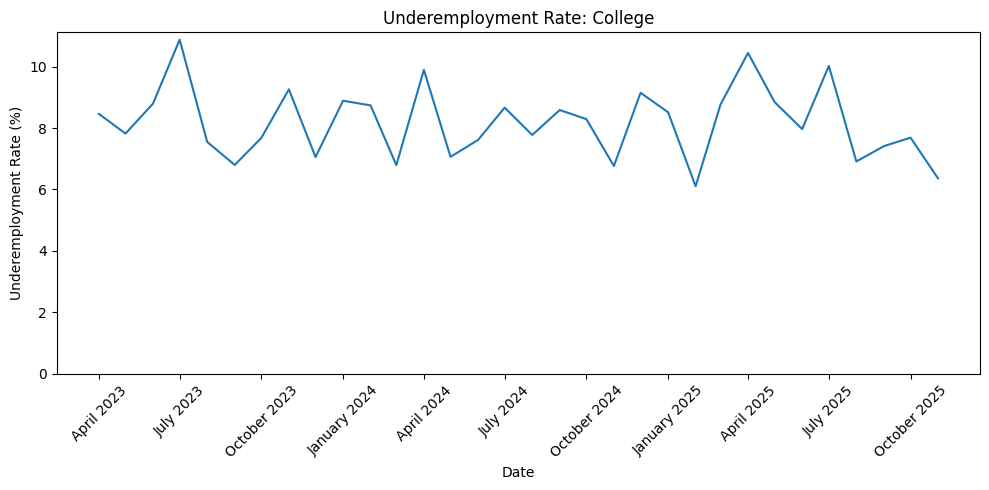

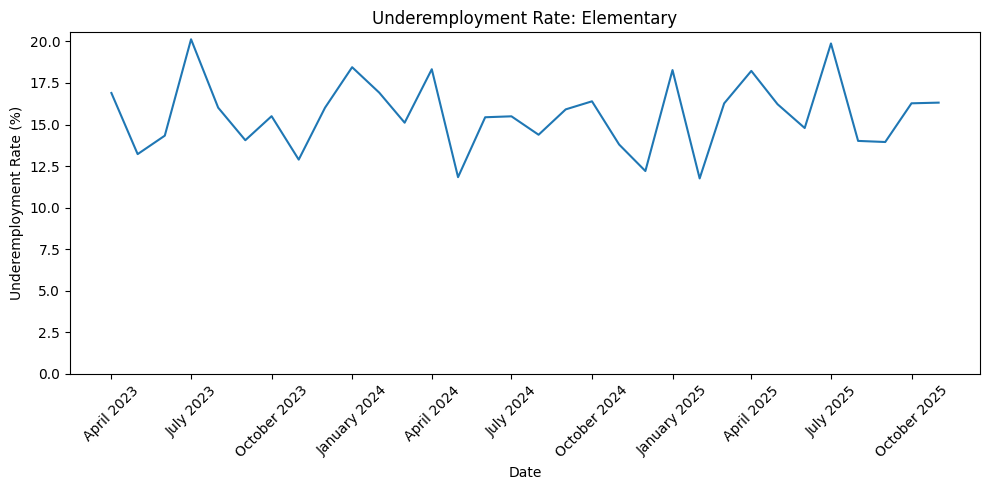

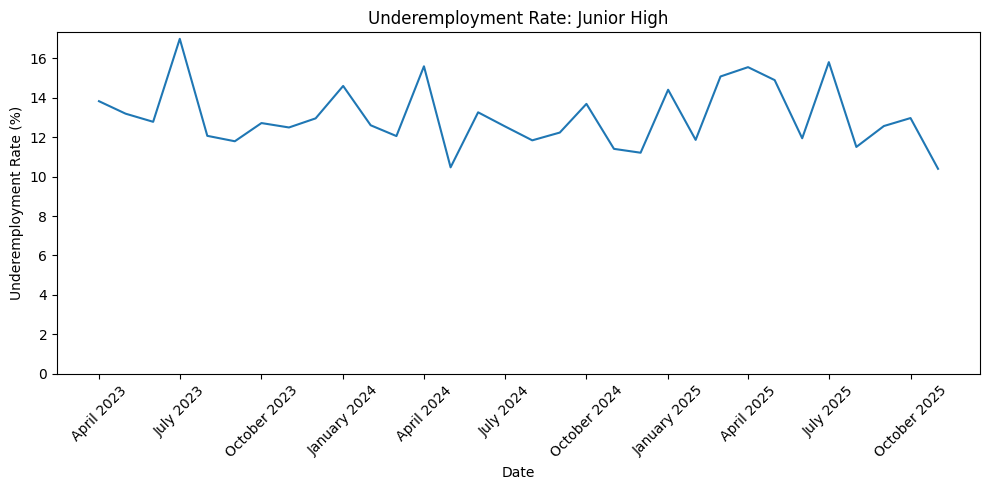

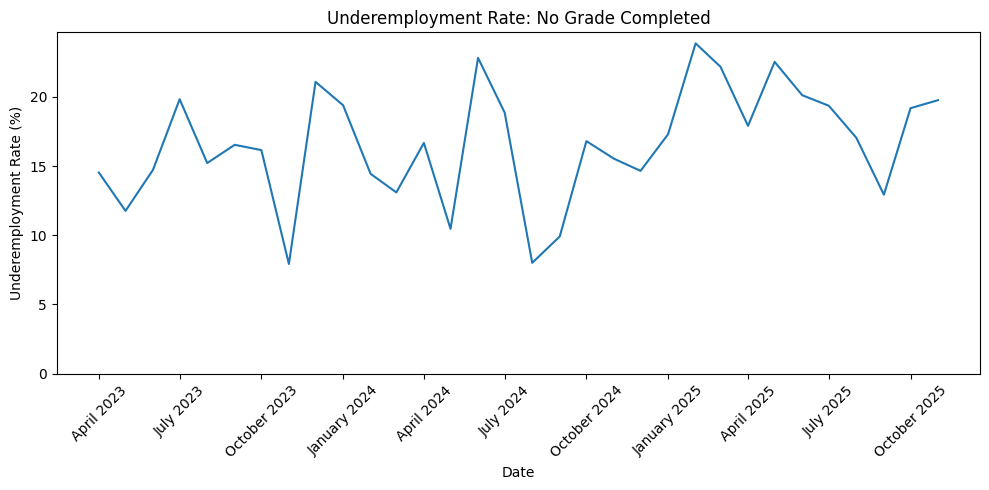

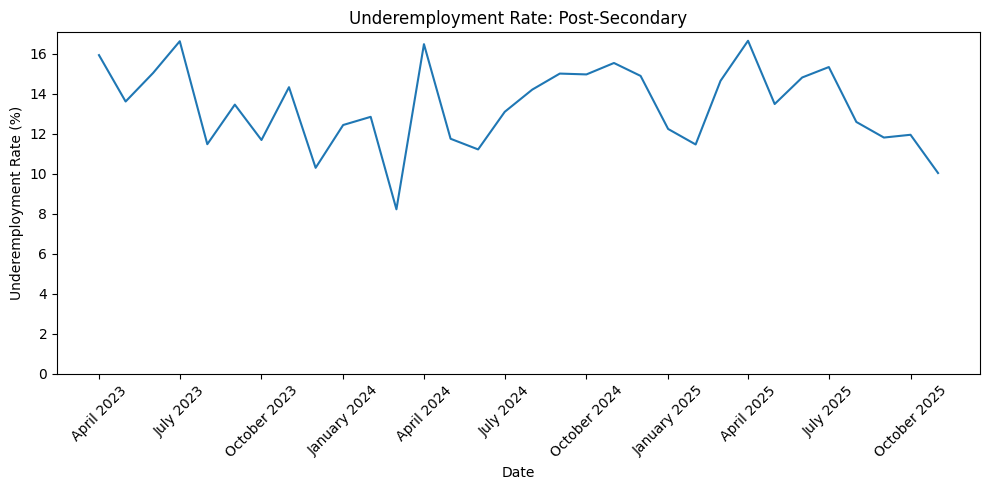

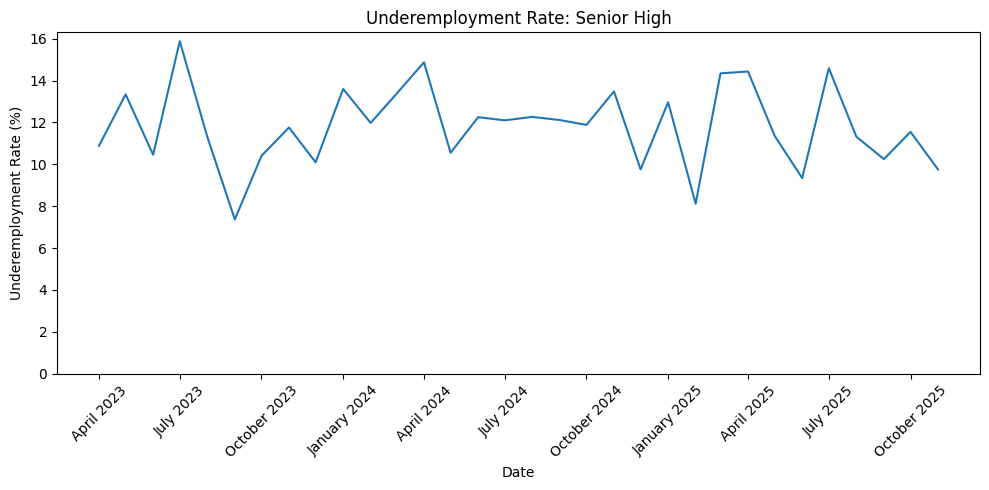

In [ ]:
# Visual 1: Underemployment Rate Trend

import matplotlib.dates as mdates

for tier in df["Education_Tier"].unique():

    data = df[df["Education_Tier"] == tier].sort_values("Date")

    plt.figure(figsize=(10, 5))
    plt.plot(data["Date"], data["Underemployment_Rate"])

    plt.title(f"Underemployment Rate: {tier}")
    plt.xlabel("Date")
    plt.ylabel("Underemployment Rate (%)")
    plt.ylim(bottom=0)

    # Show every 3 months
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%B %Y"))

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

**Visual 1: Underemployment Rate Trend**

The underemployment rates varied across education levels from 2023 to 2025, with lower education levels generally showing higher and more fluctuating rates. No Grade Completed reached its highest at around 24% in February 2025, while College stayed relatively lower, peaking at about 10.9% in July 2023 and reaching its lowest around 6.1% in February 2025. Several groups also showed noticeable peaks around July 2023, followed by declines in later months. This suggests that underemployment patterns differ across education levels, which can help identify groups that may need more employment support.

## Part 2: Feature Engineering and Predictors

### 2.1 What the Prepared Columns Mean

The dataset already comes with the columns needed for forecasting. The code that created them is not in this notebook, so this table describes them based on the data.

| Column | What it means |
|---|---|
| Underemployment_Rate | Underemployed workers divided by employed workers, as a percentage, for one education tier in one month |
| Lag1_Rate, Lag2_Rate, Lag3_Rate | The same tier's rate 1, 2, and 3 months earlier |
| Rolling3_Rate | Average of the previous three monthly rates (Lag1 to Lag3). Not used as a predictor |
| Target | The next month's underemployment rate. This is what the models try to predict |

The data starts in April 2023 because each row needs three earlier months for its lags. It ends in November 2025 because each row needs the following month as its target.

### 2.2 First Look: Predictors and Target

This first pass separates `X` and `y` using every column except `Target`. It is only a preview. The predictors actually used for modeling are chosen in 2.3, and some of these columns (such as `Date` and the raw worker counts) are not used.

In [ ]:
# Separate the predictor variables (X) from the target variable (y).
# X contains the information used to make predictions.
# y contains the one-month-ahead underemployment rate we want to predict.

X = df.drop(columns=["Target"])
y = df["Target"]

print("Predictors (X):")
print(X.columns.tolist())

print("\nTarget (y):")
print(y.name)

Predictors (X):
['Date', 'Year', 'Month', 'Underemployed', 'Employed', 'Education_Tier', 'Underemployment_Rate', 'National_Employment_Rate', 'National_Unemployment_Rate', 'National_Underemployment_Rate', 'Lag1_Rate', 'Lag2_Rate', 'Lag3_Rate', 'Rolling3_Rate']

Target (y):
Target


### 2.3 Choose the Predictors

The target (y) is the next month's Underemployment Rate. The predictors (X) are:

* **Categories:** Education Tier and Month
* **Numbers:** the current Underemployment Rate and the rates from the previous one, two, and three months (Lag1, Lag2, Lag3)

Recent rates capture the trend, while education tier and month account for differences between groups and monthly patterns.

In [ ]:
# Predictor variables used by the models.

categorical_features = ["Education_Tier", "Month"]

numerical_features = [
    "Underemployment_Rate",
    "Lag1_Rate",
    "Lag2_Rate",
    "Lag3_Rate",
]

features = categorical_features + numerical_features

print("Features:")
print(features)

Features:
['Education_Tier', 'Month', 'Underemployment_Rate', 'Lag1_Rate', 'Lag2_Rate', 'Lag3_Rate']


## Part 3: Train Test Split and Preprocessing

### 3.1 Chronological Train Test Split

Because this is forecasting, the data is split by time and not randomly. The first 80% of months are used for training and the latest 20% for testing, so the models are tested on months they have not seen, just like real forecasting. All education tiers from the same month stay together.

The output shows 150 training rows (April 2023 to April 2025) and 42 testing rows (May 2025 to November 2025).

In [ ]:
# Sort the dataset chronologically
df = df.sort_values(["Date", "Education_Tier"]).reset_index(drop=True)

X = df[features]
y = df["Target"]

print("Features:")
print(X.columns.tolist())
print("\nTarget:")
print(y.name)

# Get the unique dates in chronological order
dates = sorted(df["Date"].unique())

# Use 80% of the dates for training
cutoff_idx = int(len(dates) * 0.80)
cutoff_date = dates[cutoff_idx]

# Chronological split: the past for training, the latest months for testing
train_df = df[df["Date"] < cutoff_date].copy()
test_df = df[df["Date"] >= cutoff_date].copy()

# Separate predictors and target
X_train = train_df[features]
y_train = train_df["Target"]

X_test = test_df[features]
y_test = test_df["Target"]

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training period:", train_df["Date"].min(), "to", train_df["Date"].max())
print("Testing period:", test_df["Date"].min(), "to", test_df["Date"].max())

Features:
['Education_Tier', 'Month', 'Underemployment_Rate', 'Lag1_Rate', 'Lag2_Rate', 'Lag3_Rate']

Target:
Target

Training shape: (150, 6)
Testing shape: (42, 6)
Training period: 2023-04-01 00:00:00 to 2025-04-01 00:00:00
Testing period: 2025-05-01 00:00:00 to 2025-11-01 00:00:00


### 3.2 Preprocessing

Education Tier and Month are converted into 0/1 columns (one hot encoding) because models need numbers. The four rate columns are used as they are. Every model uses this same preprocessing so the comparison is fair.

In [ ]:
# Creating preprocessor pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


## Part 4: Model Training

### 4.1 The Four Models

* **Linear Regression:** fits a straight line relationship between the predictors and the target.
* **Ridge Regression:** like Linear Regression, but with a penalty that keeps the weights small (alpha = 5.0).
* **Lasso Regression:** also uses a penalty (alpha = 0.05) and can shrink weak predictors to zero.
* **Random Forest:** averages many decision trees (200 trees, maximum depth of 5).

Each model uses the same predictors and preprocessing.

In [ ]:
# Creating the four regression models

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=5.0))
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

lasso_model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", Lasso(
            alpha=0.05,
            max_iter=10000,
            random_state=42
        ))
    ])

print("Regression Models created successfully.")

Regression Models created successfully.


### 4.2 Train the Models

Each model learns from the training set (150 rows).

In [ ]:
# Training each model

linear_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

print("All models trained successfully.")

All models trained successfully.


### 4.3 Generate Predictions

Predictions are made for both the training and testing data. The table shows the first 10 test rows, with the actual values next to each model's prediction.

In [ ]:
# Generate predictions for both training and testing data.

linear_train_pred = linear_model.predict(X_train)
linear_test_pred = linear_model.predict(X_test)

ridge_train_pred = ridge_model.predict(X_train)
ridge_test_pred = ridge_model.predict(X_test)

random_forest_train_pred = random_forest_model.predict(X_train)
random_forest_test_pred = random_forest_model.predict(X_test)

lasso_train_pred = lasso_model.predict(X_train)
lasso_test_pred = lasso_model.predict(X_test)

print("Predictions generated successfully.")

Predictions generated successfully.


In [ ]:
# Prediction Results

results = pd.DataFrame({
    "Actual": y_test.values,
    "Linear Regression": linear_test_pred,
    "Ridge Regression": ridge_test_pred,
    "Random Forest": random_forest_test_pred,
    "Lasso": lasso_test_pred
})

display(results.head(10))

,Actual,Linear Regression,Ridge Regression,Random Forest,Lasso
0,7.964643,8.578404,9.386552,8.636126,8.811076
1,14.788073,15.841071,15.975048,15.478260,15.439416
2,11.948782,13.493396,14.442513,14.003473,13.926107
3,20.129083,16.691560,19.795960,17.915349,18.547705
4,14.819455,13.688951,14.246947,13.920533,13.723394
5,9.342589,12.300451,12.894341,13.498885,12.713009
6,10.022491,10.126377,10.536001,8.011704,10.279569
7,19.879384,17.323807,17.198535,15.725281,16.926423
8,15.813207,14.892772,15.099728,14.202007,14.989522
9,19.364738,18.096994,19.589920,17.886359,19.009353


## Part 5: Model Evaluation

### 5.1 Evaluation Metrics

* **MAE:** the average size of the prediction error. For example, an MAE of 1.6 means predictions are off by about 1.6 percentage points on average. Lower is better.
* **RMSE:** like MAE, but it gives more weight to large errors. Lower is better.
* **R²:** how much of the ups and downs in the target the model explains. Higher is better.

Both training and testing results are checked. Training shows how well a model fits data it has seen. Testing shows how well it forecasts new months.

### 5.2 Test Results

In [ ]:
# Evaluate each model using the testing data.

metrics = []

models = {
    "Linear Regression": linear_test_pred,
    "Ridge Regression": ridge_test_pred,
    "Random Forest": random_forest_test_pred,
    "Lasso": lasso_test_pred
}

for name, predictions in models.items():
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    metrics.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

metrics_df = pd.DataFrame(metrics)
metrics_df = metrics_df.round(4)

display(metrics_df)

,Model,MAE,RMSE,R²
0,Linear Regression,1.6072,2.1555,0.7050
1,Ridge Regression,1.6934,2.1996,0.6928
2,Random Forest,2.1062,2.5430,0.5894
3,Lasso,1.7556,2.2349,0.6829


### 5.3 Training Results

In [ ]:
# Evaluate the models on the training data.

train_metrics = []

train_models = {
    "Linear Regression": linear_train_pred,
    "Ridge Regression": ridge_train_pred,
    "Random Forest": random_forest_train_pred,
    "Lasso": lasso_train_pred
}

for name, predictions in train_models.items():
    mae = mean_absolute_error(y_train, predictions)
    rmse = np.sqrt(mean_squared_error(y_train, predictions))
    r2 = r2_score(y_train, predictions)

    train_metrics.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

train_metrics_df = pd.DataFrame(train_metrics).round(4)

display(train_metrics_df)

,Model,MAE,RMSE,R²
0,Linear Regression,1.5033,2.1624,0.6337
1,Ridge Regression,1.6429,2.2558,0.6013
2,Random Forest,1.5084,2.0338,0.6760
3,Lasso,1.6432,2.2803,0.5926


### 5.4 Lag 1 Persistence Baseline

The baseline uses a simple rule with no learning: next month's rate is predicted to be the same as this month's rate. It gives us a reference point, because a model is only useful if it beats this simple rule. In the tables it appears as the Persistence Baseline row.

In [ ]:
# Lag-1 Persistence Baseline
# Use the current month's rate to predict the next month's rate.

baseline_predictions = test_df["Underemployment_Rate"]

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)
baseline_r2 = r2_score(y_test, baseline_predictions)

baseline_results = pd.DataFrame([{
    "Model": "Lag-1 Persistence Baseline",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "R²": baseline_r2
}]).round(4)

display(baseline_results)

,Model,MAE,RMSE,R²
0,Lag-1 Persistence Baseline,2.3495,3.0134,0.4234


## Part 6: Compare the Models

### 6.1 Training vs Testing Performance

Training and testing metrics side by side for the four models. A big gap between the two can be a sign of overfitting.

In [ ]:
# Comparing Models

models = {
    "Linear Regression": (linear_train_pred, linear_test_pred),
    "Ridge Regression": (ridge_train_pred, ridge_test_pred),
    "Random Forest": (random_forest_train_pred, random_forest_test_pred),
    "Lasso": (lasso_train_pred, lasso_test_pred)
}

metrics = []

for name, (train_pred, test_pred) in models.items():
    metrics.append({
        "Model": name,
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Train R²": r2_score(y_train, train_pred),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test R²": r2_score(y_test, test_pred)
    })

metrics_df = pd.DataFrame(metrics).round(4)

display(metrics_df)

,Model,Train MAE,Train RMSE,Train R²,Test MAE,Test RMSE,Test R²
0,Linear Regression,1.5033,2.1624,0.6337,1.6072,2.1555,0.7050
1,Ridge Regression,1.6429,2.2558,0.6013,1.6934,2.1996,0.6928
2,Random Forest,1.5084,2.0338,0.6760,2.1062,2.5430,0.5894
3,Lasso,1.6432,2.2803,0.5926,1.7556,2.2349,0.6829


### 6.2 Test Results Including the Baseline

All four models and the baseline on the same test months (May to November 2025), sorted by MAE.

In [ ]:
# Combine the four models and the baseline into one test set table.

test_comparison = pd.concat(
    [
        metrics_df[["Model", "Test MAE", "Test RMSE", "Test R²"]].rename(
            columns={"Test MAE": "MAE", "Test RMSE": "RMSE", "Test R²": "R²"}
        ),
        baseline_results,
    ],
    ignore_index=True,
).sort_values("MAE").reset_index(drop=True)

display(test_comparison)

**What the table shows**

* All four models beat the baseline on all three metrics.
* Linear Regression is the best on this test split (MAE 1.6072, RMSE 2.1555, R² 0.7050). The baseline scored MAE 2.3495, RMSE 3.0134, and R² 0.4234, so Linear Regression's MAE is about 32% lower.
* The order by MAE is Linear Regression, Ridge, Lasso, Random Forest, then the baseline. Random Forest is the weakest of the four models, but it still beats the baseline.

This is one test split of only 7 months. Part 7 checks whether the result holds up.

## Part 7: Rolling Time Series Validation

### 7.1 Why and How

A single test split covers only 7 months, so the result may depend on those particular months. Rolling validation repeats the test four times. Each fold trains on earlier months and tests on the next 6 months, so the models never see the future.

* `TimeSeriesSplit` with 4 folds is applied to the 32 months.
* All education tiers from the same month stay in the same set.
* The baseline is scored on the same validation months as the models.

| Fold | Training months | Validation months |
|---|---|---|
| 1 | April 2023 to November 2023 | December 2023 to May 2024 |
| 2 | April 2023 to May 2024 | June 2024 to November 2024 |
| 3 | April 2023 to November 2024 | December 2024 to May 2025 |
| 4 | April 2023 to May 2025 | June 2025 to November 2025 |

Fold 4 covers almost the same months as the final test split. The code prints the results for each fold, then the average across all four folds (sorted by MAE).

In [ ]:
# Rolling Time-Series Validation
# Keep all education levels from the same month together.

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit

# Use unique months so one month cannot appear in both
# training and validation within the same fold.
unique_dates = np.sort(df["Date"].unique())

tscv = TimeSeriesSplit(n_splits=4)

models_to_validate = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Random Forest": random_forest_model,
    "Lasso": lasso_model
}

validation_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(unique_dates), start=1
):
    train_dates = unique_dates[train_idx]
    val_dates = unique_dates[val_idx]

    fold_train = df[df["Date"].isin(train_dates)].copy()
    fold_val = df[df["Date"].isin(val_dates)].copy()

    X_fold_train = fold_train[features]
    y_fold_train = fold_train["Target"]

    X_fold_val = fold_val[features]
    y_fold_val = fold_val["Target"]

    # Evaluate the four machine learning models.
    for name, original_model in models_to_validate.items():
        model = clone(original_model)

        model.fit(X_fold_train, y_fold_train)
        predictions = model.predict(X_fold_val)

        validation_results.append({
            "Fold": fold,
            "Model": name,
            "MAE": mean_absolute_error(
                y_fold_val, predictions
            ),
            "RMSE": np.sqrt(mean_squared_error(
                y_fold_val, predictions
            )),
            "R²": r2_score(y_fold_val, predictions)
        })

    # Evaluate the persistence baseline on the same dates.
    baseline_predictions = fold_val["Underemployment_Rate"]

    validation_results.append({
        "Fold": fold,
        "Model": "Lag-1 Persistence Baseline",
        "MAE": mean_absolute_error(
            y_fold_val, baseline_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_fold_val, baseline_predictions
        )),
        "R²": r2_score(y_fold_val, baseline_predictions)
    })

# Show performance for each validation fold.
validation_df = pd.DataFrame(validation_results)

display(validation_df.round(4))

# Summarize average performance across all four folds.
validation_summary = (
    validation_df
    .groupby("Model")[["MAE", "RMSE", "R²"]]
    .mean()
    .sort_values("MAE")
    .round(4)
)

print("Average performance across rolling validation folds:")
display(validation_summary)


,Fold,Model,MAE,RMSE,R²
0,1,Linear Regression,2.2788,3.0678,0.2646
1,1,Ridge Regression,1.9831,2.6542,0.4495
2,1,Random Forest,2.1323,2.7933,0.3903
3,1,Lasso,1.9510,2.5906,0.4756
4,1,Lag-1 Persistence Baseline,3.0574,3.8983,-0.1875
5,2,Linear Regression,2.1628,2.7107,0.1172
6,2,Ridge Regression,1.9627,2.5705,0.2062
7,2,Random Forest,1.5220,2.0857,0.4773
8,2,Lasso,1.8738,2.4685,0.2679
9,2,Lag-1 Persistence Baseline,1.5819,2.5936,0.1918


Average performance across rolling validation folds:


,MAE,RMSE,R²
Model,,,
Lasso,1.9772,2.6126,0.4674
Ridge Regression,1.9978,2.6187,0.4568
Random Forest,2.0607,2.6706,0.4650
Linear Regression,2.1415,2.9178,0.3253
Lag-1 Persistence Baseline,2.4645,3.2280,0.1922


### 7.2 How Consistently Did Each Model Beat the Baseline?

Count the folds where each model had a lower error than the baseline.

In [ ]:
# Count the folds where each model had a lower error than the baseline.

baseline_name = "Lag-1 Persistence Baseline"

fold_wins = {}
for metric in ["MAE", "RMSE"]:
    table = validation_df.pivot(index="Fold", columns="Model", values=metric)
    beats_baseline = table.drop(columns=baseline_name).lt(
        table[baseline_name], axis=0
    )
    fold_wins[f"Folds beating baseline ({metric})"] = beats_baseline.sum()

fold_wins_df = pd.DataFrame(fold_wins).astype(int)
fold_wins_df["Total folds"] = validation_df["Fold"].nunique()

display(fold_wins_df)

### 7.3 What the Rolling Validation Shows

* **Lasso is best on average** across all three metrics (MAE 1.9772, RMSE 2.6126, R² 0.4674). Ridge (MAE 1.9978, RMSE 2.6187, R² 0.4568) and Random Forest (MAE 2.0607, RMSE 2.6706, R² 0.4650) are very close, so the gaps among these three are small.
* **Linear Regression is the weakest of the four models** (MAE 2.1415, RMSE 2.9178, R² 0.3253). It did well in fold 4 (R² 0.7038), which is almost the same period as the final test split, but much worse in folds 1 to 3 (R² 0.1172 to 0.2646). It also had a higher RMSE than the baseline in folds 2 and 3.
* **All four models beat the baseline on average** (baseline MAE 2.4645, RMSE 3.2280, R² 0.1922). Ridge, Lasso, and Random Forest had a lower RMSE than the baseline in all 4 folds, while Linear Regression did so in only 2.
* **Results change a lot from fold to fold.** In fold 2, the baseline had a lower MAE than Linear Regression, Ridge, and Lasso. With this little data, small differences between models should be treated as close to a tie.

## Part 8: Overfitting and Underfitting

The results show some differences between the training and testing performance of the four models. Random Forest performed best on the training dataset, with the highest R² (67.60%) and lowest RMSE (2.0338), although Linear Regression had a slightly lower MAE (1.5033). On the testing dataset, Linear Regression performed best, with the lowest MAE (1.6072), RMSE (2.1555), and highest R² (70.50%).

There is some evidence of overfitting in Random Forest, as its R² dropped from 67.60% to 58.94% and its RMSE increased from 2.0338 to 2.5430. There is no clear evidence of severe underfitting, since all models achieved reasonable test R² values and all beat the baseline on the test split. Linear Regression had a relatively small change in RMSE, from 2.1624 in training to 2.1555 in testing.

One thing to note: Linear Regression scored higher on the test set (R² 70.50%) than on the training set (R² 63.37%). This is unusual, so it is worth double checking with the rolling validation in Part 7.

## Part 9: Backtest Results (Past Months)

These charts check the model on months where we already know the answer (May to November 2025). Each prediction is a one month ahead forecast made from earlier data, shown next to the actual value. The real forecast, for a month with no data yet, is in Part 11.

The charts use Linear Regression, the model that scored best on the final test split.

### Visual 2: Actual vs Predicted

**Note on the dates:** the date on the x axis is the month the prediction was made from. Each point compares the forecast with the actual rate for the following month. For example, the May 2025 point is the forecast for June 2025.

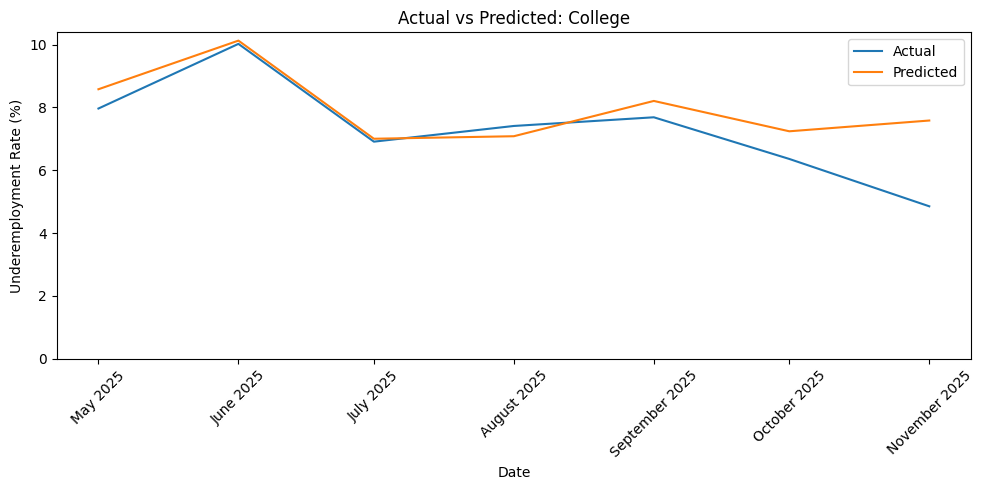

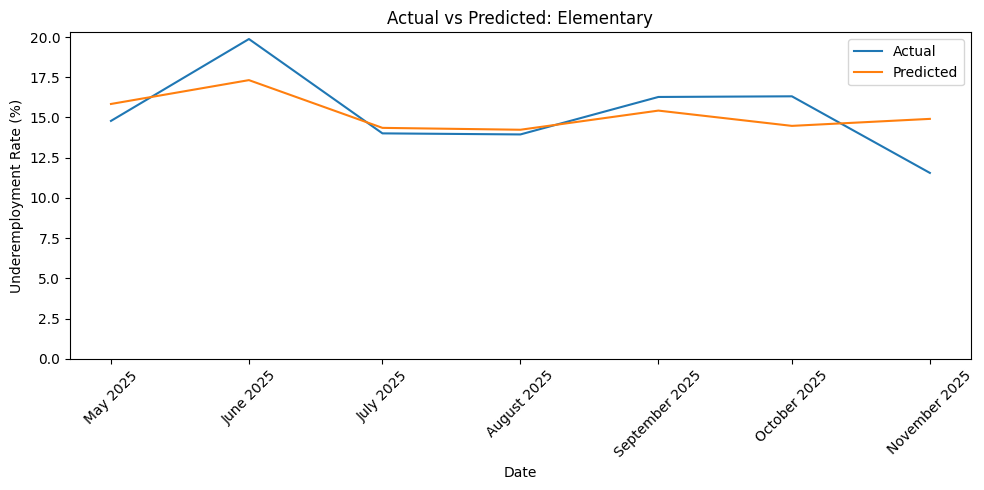

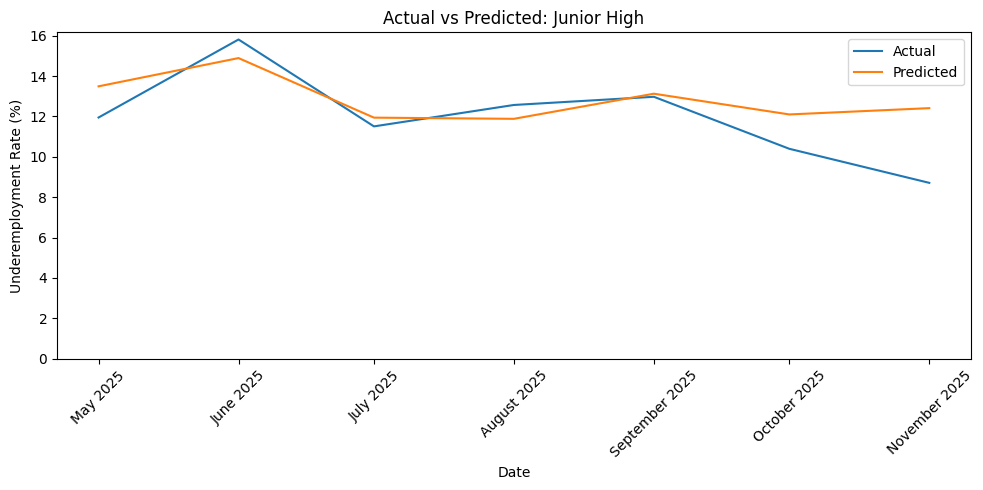

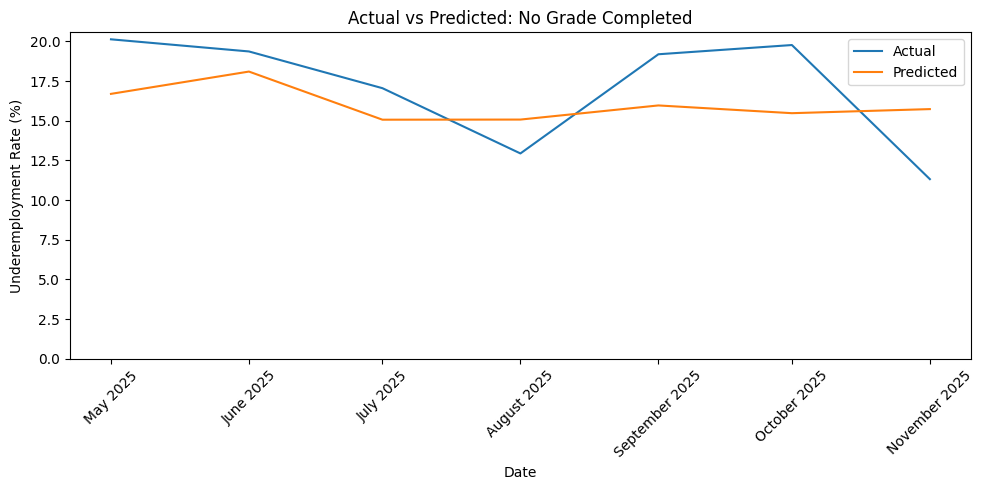

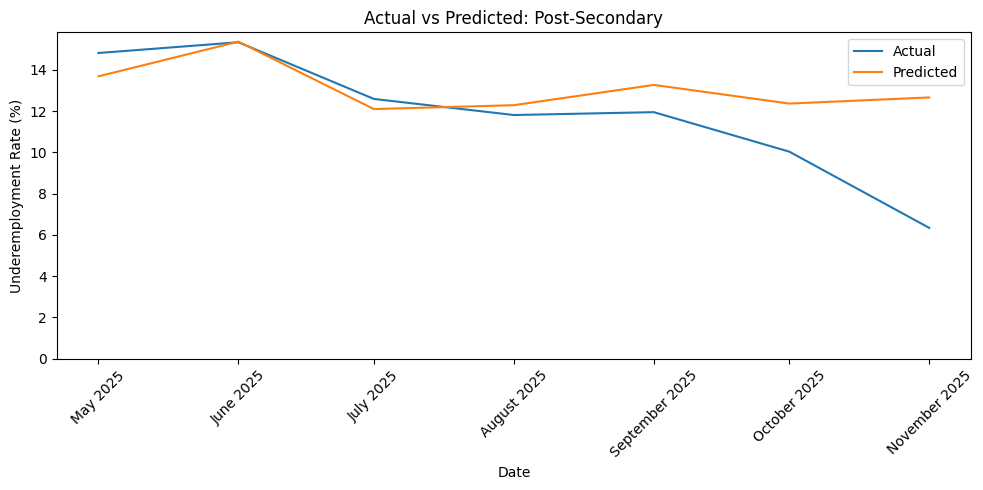

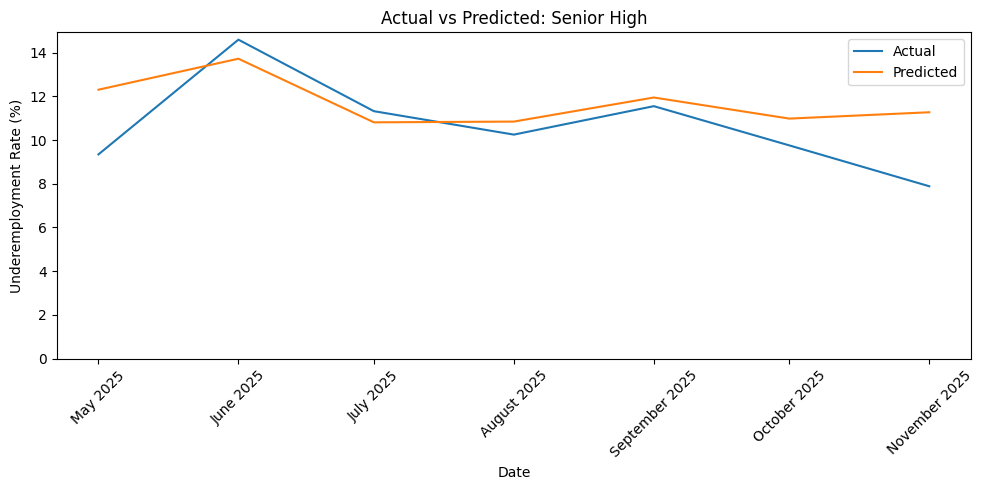

In [ ]:
# Visual 2: Actual vs Predicted

for tier in test_df["Education_Tier"].unique():

    mask = test_df["Education_Tier"] == tier

    dates = test_df.loc[mask, "Date"]

    plt.figure(figsize=(10, 5))

    plt.plot(
        dates,
        y_test.loc[mask],
        label="Actual"
    )

    plt.plot(
        dates,
        linear_test_pred[mask],
        label="Predicted"
    )

    plt.title(f"Actual vs Predicted: {tier}")
    plt.xlabel("Date")
    plt.ylabel("Underemployment Rate (%)")
    plt.ylim(bottom=0)

    # Show each test month
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%B %Y"))

    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

**Visual 2: Actual vs Predicted**

The predictions follow the general pattern of the actual rates, and some education groups match very closely. College had one of the closest matches, especially in June and July 2025, where the predicted and actual values were almost the same. Post-Secondary also matched closely around June and July 2025, and Junior High around September 2025.

The model had more difficulty with sharper changes, such as the decline in College and Post-Secondary toward November 2025, where actual rates dropped but the predictions stayed flat. No Grade Completed had the largest gaps: its predictions stayed between about 15% and 18% while the actual rates ranged from about 11% to 20%. These are forecasts, so some difference from the actual values is expected, and the results should be treated as estimates rather than exact future values.

### Visual 3: Test R² by Model

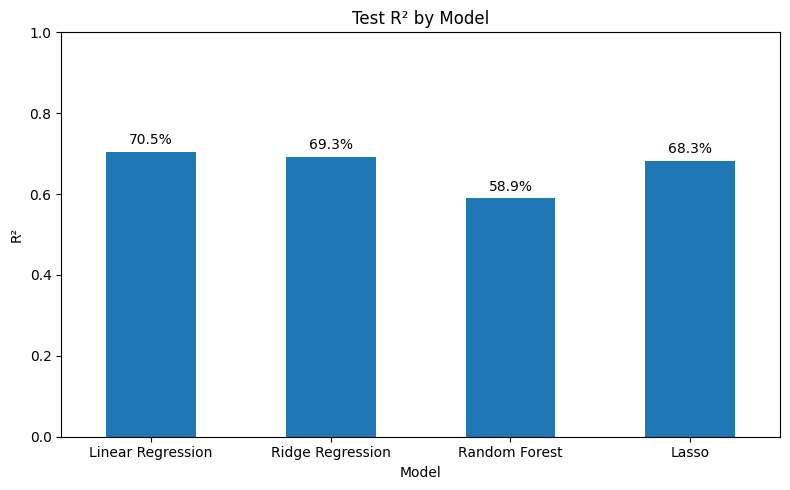

In [ ]:
# Visual 3: Model Test R²

ax = metrics_df.plot(
    x="Model",
    y="Test R²",
    kind="bar",
    figsize=(8, 5),
    legend=False
)

plt.title("Test R² by Model")
plt.ylabel("R²")
plt.xticks(rotation=0)
plt.ylim(0, 1)

# Add percentage labels on top of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{value:.1%}" for value in container.datavalues],
        padding=3
    )

plt.tight_layout()
plt.show()

**Visual 3: Test R² by Model**

On the final test split, the models had test R² values from 58.9% to 70.5%. Linear Regression was highest at 70.5%, meaning it explained about 70.5% of the variation in the test data. Ridge Regression followed at 69.3% and Lasso at 68.3%. This chart shows the final test split only. Part 7 checks the same models with rolling validation.

## Part 10: Final Comparison and Final Model

### 10.1 Summary Table

Test split results and rolling validation averages for all models and the baseline, in one table.

In [ ]:
# Summary: final test split results next to the rolling validation averages.

final_comparison = (
    test_comparison.set_index("Model").add_prefix("Test ")
    .join(validation_summary.add_prefix("Rolling Avg "))
    .round(4)
)

display(final_comparison)

### 10.2 Which Model Is Best?

* **Final test split (May to November 2025):** Linear Regression is best (MAE 1.6072, RMSE 2.1555, R² 0.7050).
* **Rolling validation (average of 4 folds):** Lasso is best (MAE 1.9772, RMSE 2.6126, R² 0.4674), and Linear Regression is the weakest of the four models.
* **Against the baseline:** all four models beat the Lag 1 Persistence Baseline on average in both checks. This means using recent rates, education tier, and month adds value compared with simply repeating last month's rate.

### 10.3 Final Model

Linear Regression is kept as the final model in this notebook. It scored best on the final test split, it is simple to explain, and the backtest charts use its predictions. However, its rolling validation results were less stable, so the choice is not clear cut. Lasso was the most consistent across folds, with Ridge and Random Forest close behind, and could be used instead.

The forecast in Part 11 uses the final model and also shows the other three models, so you can see how much they agree.

## Part 11: Forecast the Next Month (January 2026)

The backtest in Part 9 predicts months we already know. A real forecast predicts a month that has no data yet. This part forecasts January 2026 for each education tier.

### 11.1 Build the December 2025 Rows

The prepared file stops at November 2025 because every row needs a next month as its target. But the target of each November 2025 row is the December 2025 rate. So the December 2025 rows can be rebuilt from the file:

* December 2025 rate = the November row's Target
* Lag1 = the November rate, Lag2 = the November Lag1, Lag3 = the November Lag2

These rows are the inputs for predicting January 2026.

In [ ]:
# Rebuild the December 2025 rows from the November 2025 rows.

last_rows = df[df["Date"] == df["Date"].max()].copy()

dec_rows = last_rows.copy()
dec_rows["Date"] = last_rows["Date"] + pd.DateOffset(months=1)
dec_rows["Month"] = dec_rows["Date"].dt.month_name()
dec_rows["Lag3_Rate"] = last_rows["Lag2_Rate"]
dec_rows["Lag2_Rate"] = last_rows["Lag1_Rate"]
dec_rows["Lag1_Rate"] = last_rows["Underemployment_Rate"]
dec_rows["Underemployment_Rate"] = last_rows["Target"]
dec_rows = dec_rows.reset_index(drop=True)

display(dec_rows[["Date", "Education_Tier", "Month"] + numerical_features])

### 11.2 Forecast January 2026

Each model is retrained on all 192 rows (not just the training set), then used to predict January 2026 for each tier. The table also shows the December 2025 rate, which is what the Persistence Baseline would predict.

In [ ]:
# Retrain each model on all available data and forecast January 2026.

X_all = df[features]
y_all = df["Target"]

forecast_table = pd.DataFrame({
    "Education_Tier": dec_rows["Education_Tier"],
    "Dec 2025 Actual": dec_rows["Underemployment_Rate"]
})

for name, original_model in models_to_validate.items():
    model = clone(original_model)
    model.fit(X_all, y_all)
    forecast_table[name] = model.predict(dec_rows[features])

forecast_table = forecast_table.set_index("Education_Tier").round(2)

print("Forecast of the underemployment rate (%) for January 2026")
display(forecast_table)

### 11.3 Forecast Chart

The solid line shows the actual 2025 rates. The dashed orange line goes to the January 2026 forecast of the final model. To use a different model, change `final_model_name` (for example, to `"Lasso"`).

In [ ]:
# Chart: 2025 actual rates and the January 2026 forecast.

final_model_name = "Linear Regression"

# Actual rates, with the December 2025 rates added at the end.
history = pd.concat([
    df[["Date", "Education_Tier", "Underemployment_Rate"]],
    dec_rows[["Date", "Education_Tier", "Underemployment_Rate"]]
])
history = history[history["Date"] >= "2025-01-01"]

jan_date = dec_rows["Date"].iloc[0] + pd.DateOffset(months=1)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, tier in zip(axes.flatten(), sorted(history["Education_Tier"].unique())):
    data = history[history["Education_Tier"] == tier].sort_values("Date")
    forecast_value = forecast_table.loc[tier, final_model_name]

    ax.plot(data["Date"], data["Underemployment_Rate"],
            marker="o", label="Actual")
    ax.plot([data["Date"].iloc[-1], jan_date],
            [data["Underemployment_Rate"].iloc[-1], forecast_value],
            linestyle="--", marker="o", color="orange",
            label="Forecast (Jan 2026)")

    ax.set_title(tier)
    ax.set_ylabel("Underemployment Rate (%)")
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="x", rotation=45)
    ax.legend()

plt.suptitle(f"January 2026 Forecast ({final_model_name})")
plt.tight_layout()
plt.show()

### 11.4 How to Read the Forecast

* Each forecast is an estimate for one month ahead, not an exact value. For Linear Regression, the typical miss was about 1.6 percentage points on the test split, and between 1.5 and 2.6 points across the rolling folds. Use this as a rough guide to how far a forecast can be off.
* Look at the table across models. If the models give similar numbers for a tier, the forecast is easier to trust. If they differ a lot, be more careful with it.
* Small tiers such as No Grade Completed are harder to forecast. The backtest showed the largest gaps there.

## Part 12: Conclusion

### 12.1 What the Results Mean

* On the final test split, the forecasts were off by about 1.6 percentage points on average (MAE 1.6072), and the model explained about 70.5% of the changes in next month's rate (R² 0.7050).
* Across the rolling folds, Linear Regression's MAE ranged from 1.5351 to 2.5893, so the typical error depends on which months are being forecast.
* The notebook now produces a one month ahead forecast for each education tier (January 2026), using models trained on all available data.

### 12.2 Limitations

* The data is small: 192 rows in total and only 7 test months. The fold results show that performance can change from one period to another.
* The models forecast only one month ahead.
* Sudden moves were not captured well, such as the drop in College and Post-Secondary in late 2025 and the swings in No Grade Completed.